# 2 Ising model

## Ising model

<div style="background-color: #f0f8ff; border: 2px solid #4682b4; padding: 10px;">

**Note:** This notebook contains the code for section 2.2 from the book
    
**Simulation of Complex Systems**
Aykut Argun, Agnese Callegari, and Giovanni Volpe<br>
IOP Publishing, Bristol, UK, 2021<br>
ISBN: 978-0-7503-3843-1<br>
[https://iopscience.iop.org/book/mono/978-0-7503-3843-1](https://iopscience.iop.org/book/mono/978-0-7503-3843-1)
    
    
You can find the other notebooks on the [Simulation of Complex Systems GitHub page](../../)

</div>

<a id="local-energy"></a>
### 2.2 Ising model 

Each lattice site has spin $\sigma_{i,j}=\pm1$. 

A nearest-neighbor spin interacts with its four side neighbors and with the applied magnetic field $H$:

$$E_{i,j}=-H\sigma_{i,j}-J\sigma_{i,j}M_{i,j}, $$

with

$$M_{i,j}=\sigma_{i-1,j}+\sigma_{i+1,j}+\sigma_{i,j-1}+\sigma_{i,j+1}.$$

(Textbook Eq. 2.2; the sum is over the **four side neighbors**) 

We choose: $k_B=1$ 

Initially $J=1$, $H = 0$. 

With $J>0$ equal neighboring spins are favored; with $J<0$ opposite neighbors are favored.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
import sys
sys.path.insert(0, "../02_modules")
import ising_model as im
import ising_visualize as vis

<a id="single-spin"></a>
We start by **creating a random lattice**. 

We use *periodic boundary conditions* (PBC): each spin has exactly four neighbours.

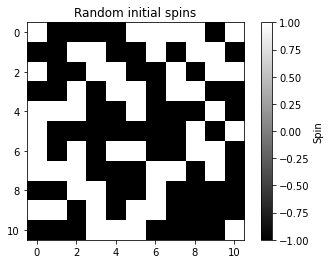

In [2]:
rng = np.random.default_rng()

N = 11
spins = 2 * rng.integers(0, 2, size=(N, N)) - 1
plt.imshow(spins, 
           cmap="gray", vmin=-1, vmax=1, interpolation="nearest")
plt.title("Random initial spins")
plt.colorbar(label="Spin")
plt.show()

In [3]:
i = rng.integers(N)
j = rng.integers(N)
M = (spins[(i-1) % N, j] + spins[(i+1) % N, j]
     + spins[i, (j-1) % N] + spins[i, (j+1) % N])
print(f"Spin at ({i}, {j}): {spins[i,j]}; neighbor sum: {M}")

Spin at (6, 4): 1; neighbor sum: -2


<a id="spin-update"></a>
We proceed with the **spin update** for a **single spin**.

For this site the energies of the two possible future states are

$$E_+=-(H+JM),\qquad E_-=H+JM.$$

The probability that the new spin is $+1$ is (textbook Eqs. 2.1–2.2)

$$p_+=\frac{e^{-E_+/ k_B T}}{e^{-E_+/k_B T}+e^{-E_-/ k_B T}}.$$

In [4]:
T = 2.0
J = 1.0
H = 0.0
kB = 1.0

E_plus = -(H + J * M)
E_minus = H + J * M

p_plus = 0.5 * (1 + np.tanh((H + J * M) / (kB * T)))
p_minus = 0.5 * (1 + np.tanh(-(H + J * M) / (kB * T))) 
# p_minus + p_plus = 1

print(f"E(+1)={E_plus:.0f}, E(-1)={E_minus:.0f};")
print(f"p(+1)={p_plus:.3f}, p(-1)={p_minus:.3f}")

E(+1)=2, E(-1)=-2;
p(+1)=0.119, p(-1)=0.881


In [5]:
spins[i, j] = 1 if rng.random() < p_plus else -1
print("Updated spin:", spins[i, j])

Updated spin: -1


<a id="updates"></a>
We repeat the procedure to realize **random sequential updates**.

We randomly update a fraction (usually ~10%) of lattice sites per *step* (Exercise 2.2). 

In [6]:
f = 0.1
updates = round(0.1 * N * N)  
for attempt in range(updates):
    i, j = rng.integers(N, size=2)
    M = (spins[(i - 1) % N, j] + spins[(i + 1) % N, j]
         + spins[i,(j - 1) % N] + spins[i,(j + 1) % N])
    p_plus = 0.5 * (1 + np.tanh((H + J * M) / (kB * T)))
    
    spins[i, j] = 1 if rng.random() < p_plus else -1

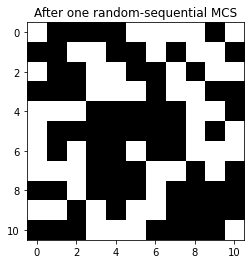

In [7]:
plt.imshow(spins, 
           cmap="gray", vmin=-1, vmax=1, interpolation="nearest")
plt.title("After one random-sequential MCS")
plt.show()

<a id="temperature"></a>
Let's check what happens reiterating the update for different temperatures

In [8]:
temperatures = [1.0, 2.269, 5.0]

N = 32
H = 0.0
J = 1.0
n_steps = 500
f = 0.1

n_updates = round( f * N * N )

snapshots_start = []
snapshots_end = []
for T in temperatures:
    spins = 2 * rng.integers(0, 2, size=(N, N)) - 1
    snapshots_start.append(spins.copy())    
    for _ in range(n_steps):
        for attempt in range(n_updates):
            i, j = rng.integers(N, size=2)
            M = (spins[(i - 1) % N, j] + spins[(i + 1) % N, j]
                 + spins[i,(j - 1) % N] + spins[i,(j + 1) % N])
            p_plus = 0.5 * (1 + np.tanh(M / (kB * T)))
            spins[i, j] = 1 if rng.random() < p_plus else -1
    snapshots_end.append(spins.copy())
        

Let's plot the initial state

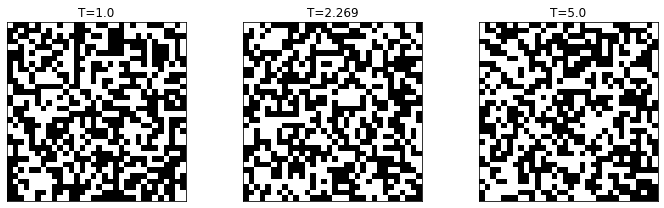

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(10, 3))
for ax, temperature, lattice in zip(axes, temperatures, 
                                    snapshots_start):
    ax.imshow(
        lattice, 
        cmap="gray", 
        vmin=-1, 
        vmax=1, 
        interpolation="nearest"
    )
    ax.set(title=f"T={temperature}", xticks=[], yticks=[])
plt.tight_layout()
plt.show()

Now the final state

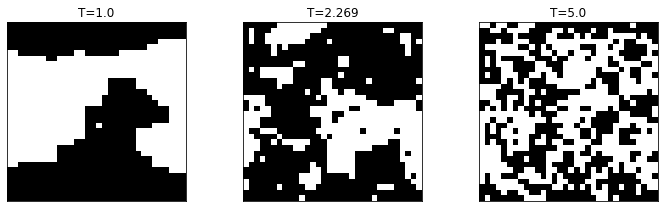

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(10, 3))
for ax, temperature, lattice in zip(axes, temperatures, 
                                    snapshots_end):
    ax.imshow(
        lattice, 
        cmap="gray", 
        vmin=-1, 
        vmax=1, 
        interpolation="nearest"
    )
    ax.set(title=f"T={temperature}", xticks=[], yticks=[])
plt.tight_layout()
plt.show()

<a id="module"></a>
Let's examine the magnetization.

Magnetization per lattice site (Eq. 2.3):

$$m=\frac{1}{N^2}\sum_{i,j}\sigma_{i,j}.$$

A configuration with large positive or negative $m$ is ordered.

$m\approx0$ can indicate disorder **or** oppositely magnetized domains, so look at spin maps as well.

Let's now use the module `ising_model.py` for the update.
We simulate the steps and calculate the magnetization.

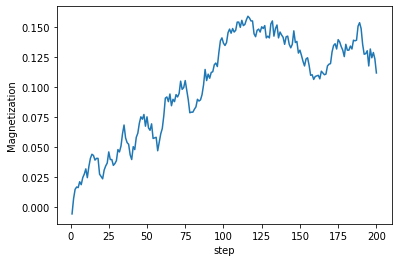

In [11]:
N = 64
T = 5.0
J = 1.0
H = 0.2  # H > 0
kB = 1.0
f = 0.1
n_skip = 1
n_steps = 200

rng = np.random.default_rng()

spins = im.random_spins(N, rng)
m = im.simulate(spins, T, n_steps, rng, J, H, kB, f, n_skip)

plt.plot(np.arange(1, len(m) + 1), m)
plt.xlabel("step")
plt.ylabel("Magnetization")
plt.show()

In [12]:
print("Magnetization:", im.magnetization(spins))
print("Total energy:", im.energy(spins, J, H))

Magnetization: 0.11181640625
Total energy: -0.42373046875


<a id="animation"></a>
Let's see one animation with pygame.

In [13]:
N = 64
T = 2.0
J = 1.0
H = 0.0
kB = 1.0
f = 0.1
n_skip = 2
n_steps = 500
window_size = 200

rng = np.random.default_rng()
spins = im.random_spins(N, rng)

spins = vis.animate_ising_model(
    spins, T, n_steps, rng, J, H, kB, f, n_skip, window_size
)

pygame 2.5.2 (SDL 2.28.3, Python 3.8.5)
Hello from the pygame community. https://www.pygame.org/contribute.html


<a id="field-and-antiferromagnet"></a>
Let's check the effect of a finite magnetic field $H$.

For temperature larger than the critical temperature: we define the magnetic susceptibility $\chi$ via $m = \chi H $

In [14]:
field_values = [ -1.0, -0.6, -0.4, -0.2, 0.0, 0.2, 0.4, 0.6, 1.0]
m_av = []
m_sig = []

N = 128
T = 5.0  # T > Tc
J = 1.0
kB = 1.0
f = 0.1
n_skip = 100
n_ini = 500
n_steps = 1000

rng = np.random.default_rng()

for H in field_values:
    spins = im.random_spins(N, rng)
    im.simulate(spins, T, n_ini, rng, J, H, kB, f, n_ini)
    m = im.simulate(spins, T, n_steps, rng, J, H, kB, f, n_skip)
    m_av.append(np.mean(m))
    m_sig.append(np.std(m))

We fit the points around $H=0$

chi = 5.640e-01 (magnetic susceptibility)
m0 = 4.069e-05 (intercept)


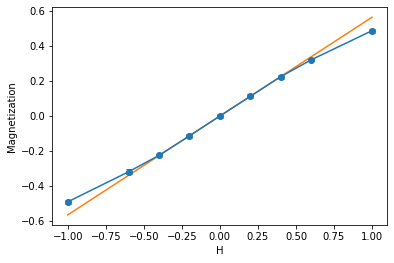

In [15]:
chi, m0 = np.polyfit(field_values[3:-3], m_av[3:-3], 1)    

print(f'chi = {chi:.3e} (magnetic susceptibility)')
print(f'm0 = {m0:.3e} (intercept)')


plt.errorbar(field_values, m_av, yerr=m_sig, fmt="o-", capsize=3)
plt.plot(field_values, chi * np.asarray(field_values) + m0)
plt.xlabel("H")
plt.ylabel("Magnetization")
plt.show()

<a id="questions"></a>

## Questions

Here you find the questions:

- [Q5: Creating the random lattice](#q5)
- [Q6: Spin update](#q6)
- [Q7: The effect of temperature](#q7)
- [Q8: Magnetization and susceptibility](#q8)
- [Q9: Implementation](#q9)

<a id="q5"></a>
**Question 5:** Creating the random lattice.

Refer to: [Single spin](#single-spin)

[Go back to questions](#questions)

a. Explain why `(i-1) % N` accesses the appropriate neighbor for `i=0`.

b. What numerical and physical differences would arise from using open boundaries instead?

c. Explain the effect of `interpolation="nearest"` in:
```python
plt.imshow(spins, 
           cmap="gray", vmin=-1, vmax=1, 
           interpolation="nearest")
```

d. What happens if we omit `interpolation="nearest"` from the command above? Try and describe its effect.

<a id="q6"></a>

**Question 6:** Spins update

Refer to: [Spin update](#spin-update)

[Go back to questions](#questions)

a. The code calculates the probability as:
```python
p_plus = 0.5 * (1 + np.tanh((H + J * M) / (kB * T)))
```
Why this expression is equivalent to the formulation of Eqs. 2.1–2.2?

b. Is the value of the spin itself (`spins[i, j]`) playing any role in the calculation of `p_plus`? Why or why not?

Focus on the lines:
```python
for attempt in range(updates):
    i, j = rng.integers(N, size=2)
```

c. Assume `N = 5` and `n_updates = 2`. What is the probability that a single spin (i.e., the same set of `i, j` ) is chosen twice? 

d. How would you modify the code to make sure you don't update twice the same spin?

e. In the random sequential update we wrote:
```python
    p_plus = 0.5 * (1 + np.tanh((H + J * M) / (kB * T)))   
    spins[i, j] = 1 if rng.random() < p_plus else -1
```
Write what would the code be if, instead of checking the probability of having a +1 spin, we would be checking the probability of getting a -1 spin.

<a id="q7"></a>
**Question 7:** Effect of temperature.

Refer to [Effect of temperature](#temperature)

[Go back to questions](#questions)

Assume `N = 32`, `H = 0.0`, `J = 1.0`, and you run for `n_steps = 5000` 

a. For the case `T = 1.0` ($T<T_c$): describe the appearance of the final snapshot. Is there always a prevalence of white (i.e., spins tend to be +1) ?

b. For `T = 2.26` ($T \approx T_c$): describe the appearance of the final snapshot. Is there always a prevalence of white (i.e., spins tend to be +1) ?

c. For `T = 10.0` ($T \gg T_c$): describe the appearance of the final snapshot. Is there always a prevalence of white (i.e., spins tend to be +1) ?


<br>Assume `N = 32`, `H = 0.0`, `J = -1.0`, and you run for `n_steps = 5000` 

d. For the case `T = 1.0` ($T<T_c$): describe the appearance of the final snapshot. Is there always a prevalence of white (i.e., spins tend to be +1) ?

e. For `T = 2.26` ($T \approx T_c$): describe the appearance of the final snapshot. Is there always a prevalence of white (i.e., spins tend to be +1) ?

f. For `T = 10.0` ($T \gg T_c$): describe the appearance of the final snapshot. Is there always a prevalence of white (i.e., spins tend to be +1) ?


<br>Assume `N = 32`, `H = 0.5`, `J = 1.0`, and you run for `n_steps = 5000` 

g. For the case `T = 1.0` ($T<T_c$): describe the appearance of the final snapshot. Is there always a prevalence of white (i.e., spins tend to be +1) ?

h. For `T = 2.26` ($T \approx T_c$): describe the appearance of the final snapshot. Is there always a prevalence of white (i.e., spins tend to be +1) ?

i. For `T = 10.0` ($T \gg T_c$): describe the appearance of the final snapshot. Is there always a prevalence of white (i.e., spins tend to be +1) ?


<a id="q8"></a>
**Question 8:** Magnetization and susceptibility

Refer to [Magnetization and susceptibility](#module) and [Effect of temperature](#temperature)

[Go back to questions](#questions)

Assume `N = 32`, `H = 0.0`, `J = 1.0`, and you run for `n_steps = 5000` 

a. For the case `T = 1.0` ($T<T_c$): Is the magnetization more close to 0, +1, -1? 

b. For the case `T = 2.26` ($T \approx T_c$): Is the magnetization more close to 0, +1, -1? 

c. For the case `T = 10.0` ($T \gg T_c$): Is the magnetization more close to 0, +1, -1? 


<br>Assume `N = 32`, `H = 0.0`, `J = -1.0`, and you run for `n_steps = 5000` 

d. For the case `T = 1.0` ($T<T_c$): Is the magnetization more close to 0, +1, -1? 

e. For the case `T = 2.26` ($T \approx T_c$): Is the magnetization more close to 0, +1, -1? 

f. For the case `T = 10.0` ($T \gg T_c$): Is the magnetization more close to 0, +1, -1? 


<br>Assume `N = 32`, `J = 1.0`, and you run for `n_steps = 5000`, `T = 5.0` ($T > T_c$)

g. For the case `H = 0.2`, is the magnetization `m` positive or negative? Why?

h. For the case `H = -0.2`, is the magnetization `m` positive or negative? Why?


<br><br>
i. How do you extract the high-temperature susceptibility $\chi$ from a numerical $m(H)$ plot?

<a id="q9"></a>
**Question 9:** Implementation

Refer to [Magnetization and susceptibility](#module) and  [ising_model.py](../02_modules/ising_model.py)

[Go back to questions](#questions)

Refer to the function `heat_bath_sweep`.

a. What is the outcome of:
```python
indices = rng.choice(Lx * Ly, size=n, replace=False)
```

b. What is the outcome of:
```python
    y, x = np.unravel_index(indices, (Ly, Lx))
```

c. Why in:
```python
    M = (
        spins[(y + 1) % Ly, x]
        + spins[(y - 1) % Ly, x]
        + spins[y, (x + 1) % Lx]
        + spins[y, (x - 1) % Lx]
    )
```
we have `(y + 1) % Ly`, `(y - 1) % Ly`, `(x + 1) % Lx`, `(x - 1) % Lx`?

d. What is the outcome of:
```python
rng.random(p_plus.shape)
```

e. What is the outcome of:
```python
spins[y, x] = np.where(rng.random(p_plus.shape) < p_plus, 1, -1)
```

f. Why `spins` is not returned by `heat_bath_sweep` ?


<br>Refer to the function `simulate`, specifically to the lines:
```python
    for step in range(n_steps):
        heat_bath_sweep(spins, T, rng, J, H, kB, f)
```

g. Is `spins` changed in  `simulate` ?


<br>Refer to the lines in this notebook:
```python
for H in field_values:
    spins = im.random_spins(N, rng)
    im.simulate(spins, T, n_ini, rng, J, H, kB, f, n_ini)
```

h. Assume we assign:<br>
`spins_before = spins.copy()` <br>
right after `spins = im.random_spins(N, rng)` 
and <br>
`spins_after = spins.copy()` <br>
after `im.simulate(spins, T, n_ini, rng, J, H, kB, f, n_ini)` in the for cycle. <br>
Is `spins_after` numerically equal to `spins_before`? Why or why not?


i. If we don't want `im.simulate` to change `spins` (i.e., we want  `spins` to reflect the condition right after initialization), how should we modify the lines above?

